Project penelitian dari tahapan pra-skripsi sampai skripsi

Memuat Dataset & Pra-pemrosesan Data

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Memuat Dataset (Sesuaikan nama file CSV Anda)
df = pd.read_csv('student_lifestyle_dataset.csv')

print("Nama-nama kolom dalam dataset:", df.columns.tolist())

# 2. Menentukan Fitur (X) dan Target (y)
target_column = 'Stress_Level'

# Hapus 'Stress_Level' dari fitur X agar tidak terjadi ValueError
X = df[[
    'Study_Hours_Per_Day',
    'Extracurricular_Hours_Per_Day',
    'Sleep_Hours_Per_Day',
    'Social_Hours_Per_Day',
    'Physical_Activity_Hours_Per_Day',
    'GPA',
    'Stress_Level'
]]

y = df[target_column]

# 3. Memastikan Target Berbentuk Numerik
if y.dtype == 'object' or y.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(y)
    print("Label target berhasil di-encode ke numerik:", np.unique(y))
else:
    y = y.astype(int)

# 4. Membagi Data Training dan Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Pra-pemrosesan data selesai! Variabel X_train dan y_train siap digunakan.")

Nama-nama kolom dalam dataset: ['Student_ID', 'Study_Hours_Per_Day', 'Extracurricular_Hours_Per_Day', 'Sleep_Hours_Per_Day', 'Social_Hours_Per_Day', 'Physical_Activity_Hours_Per_Day', 'GPA', 'Stress_Level']
Label target berhasil di-encode ke numerik: [0 1 2]
Pra-pemrosesan data selesai! Variabel X_train dan y_train siap digunakan.


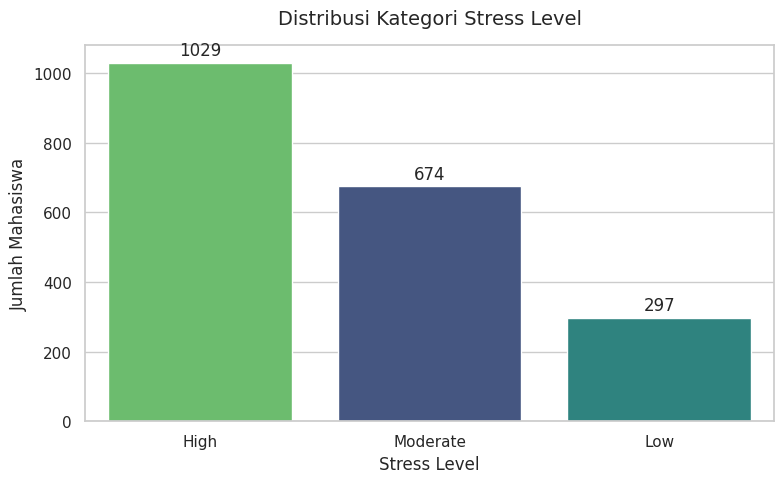

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# Membuat figure
plt.figure(figsize=(8, 5))

# Membuat countplot untuk distribusi Stress_Level dengan parameter hue agar tidak muncul FutureWarning
ax = sns.countplot(
    x='Stress_Level',
    data=df,
    palette='viridis',
    hue='Stress_Level',
    legend=False,
    order=df['Stress_Level'].value_counts().index
)

# Menambahkan judul dan label
plt.title('Distribusi Kategori Stress Level', fontsize=14, pad=15)
plt.xlabel('Stress Level', fontsize=12)
plt.ylabel('Jumlah Mahasiswa', fontsize=12)

# Menampilkan angka jumlah di atas bar
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'),
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points')

plt.tight_layout()
plt.show()

Pelatihan Model Random Forest & XGBoost

In [15]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
import joblib

# 1. Melatih Model Random Forest
print("--- Melatih Random Forest ---")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
print(f"Akurasi Random Forest: {accuracy_score(y_test, y_pred_rf):.4f}")

# 2. Melatih Model XGBoost (Tanpa parameter deprecated)
print("\n--- Melatih XGBoost ---")
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
print(f"Akurasi XGBoost: {accuracy_score(y_test, y_pred_xgb):.4f}")

# 3. Menyimpan Model Terbaik (Misal: Random Forest) ke file .pkl
joblib.dump(rf_model, 'model_rf.pkl')
print("\n✅ Model Random Forest berhasil disimpan sebagai 'model_rf.pkl'!")

# (Opsional) Jika ingin menyimpan XGBoost:
# joblib.dump(xgb_model, 'model_xgb.pkl')

--- Melatih Random Forest ---
Akurasi Random Forest: 1.0000

--- Melatih XGBoost ---
Akurasi XGBoost: 1.0000

✅ Model Random Forest berhasil disimpan sebagai 'model_rf.pkl'!


Mengunduh File Model untuk Streamlit

In [16]:
from google.colab import files
files.download('model_rf.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>